##**Task 1 – Data Preparation and Feature Engineering**
#####Study period: 1 January 2021 to 1 January 2025 (end date exclusive)
Uses yfinance, pandas and NumPy. Missing prices are not filled.

####**1.1 Ticker selection and data acquisition**

In [47]:
# Install required packages
!pip install -q yfinance lxml

# Import required libraries
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from datetime import datetime

print('pandas version:', pd.__version__)
print('NumPy version:', np.__version__)
print('yfinance version:', yf.__version__)

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.6f}'.format)

pandas version: 2.2.3
NumPy version: 2.4.6
yfinance version: 0.2.66


In [48]:
# Extract the S&P 500 constituent list from Wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0].copy()

# Record the retrieval date and prepare Yahoo Finance ticker symbols
retrieval_date = pd.Timestamp.now().date()
sp500_df['Symbol'] = sp500_df['Symbol'].astype(str)
sp500_df['Yahoo_Ticker'] = sp500_df['Symbol'].str.replace('.', '-', regex=False)
tickers = sp500_df['Yahoo_Ticker'].drop_duplicates().tolist()

print("Ticker-list retrieval date:", retrieval_date)
print("Number of tickers extracted:", len(tickers))
display(sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10))

# Preserve the ticker list and sector information
sp500_df.to_csv('sp500_ticker_list.csv', index=False)

Ticker-list retrieval date: 2026-11-24
Number of tickers extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [49]:
# Define the required study period (end date is exclusive)
start = '2021-01-01'
end = '2025-01-01'

# Download daily share data; keep Close and Adj Close separately
stock_data = yf.download(
    tickers,
    start=start,
    end=end,
    auto_adjust=False,
    actions=True,
    group_by='column',
    threads=True,
    progress=True
)

# Download the S&P 500 benchmark using the same price basis and dates
market_data = yf.download(
    '^GSPC',
    start=start,
    end=end,
    auto_adjust=False,
    actions=True,
    progress=True
)

# Standardise date indexes
stock_data = stock_data.sort_index()
market_data = market_data.sort_index()
stock_data.index = pd.to_datetime(stock_data.index).tz_localize(None)
market_data.index = pd.to_datetime(market_data.index).tz_localize(None)

print("Stock data shape:", stock_data.shape)
print("Benchmark data shape:", market_data.shape)
display(stock_data.head())
display(market_data.head())

# Preserve the downloaded source snapshots
stock_data.to_pickle('sp500_daily_data.pkl')
market_data.to_pickle('sp500_benchmark_data.pkl')

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['Q', 'HONA', 'VYLR', 'FDXF', 'SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  1 of 1 completed


Stock data shape: (1005, 4014)
Benchmark data shape: (1005, 8)


Price       Adj Close                                                      \
Ticker              A       AAPL      ABBV       ABNB       ABT      ACGL   
Date                                                                        
2021-01-04 114.009125 125.537132 84.219139 139.149994 97.269707 33.186359   
2021-01-05 114.941254 127.089195 85.090019 148.300003 98.473190 33.319485   
2021-01-06 118.093239 122.811195 84.354973 142.770004 98.268150 34.783871   
2021-01-07 121.235611 127.001892 85.257797 151.270004 99.222054 34.460564   
2021-01-08 122.100464 128.098099 85.705200 149.770004 99.498421 34.650742   

Price                                                                        \
Ticker            ACN       ADBE        ADI       ADM        ADP       ADSK   
Date                                                                          
2021-01-04 232.029373 485.339996 132.622620 42.189495 148.964630 296.839996   
2021-01-05 233.350250 485.690002 134.993149 43.010098 148.550278 301.700012   
2021-01-06 235.901611 466.309998 135.601685 44.752838 148.030106 302.869995   
2021-01-07 238.127304 477.739990 141.332764 44.355213 148.867661 315.200012   
2021-01-08 238.995880 485.100006 142.359055 44.473660 150.807343 319.850006   

Price                                                                    \
Ticker           AEE       AEP       AES       AFL       AIG        AIZ   
Date                                                                      
2021-01-04 64.388977 65.872749 18.430204 37.676277 32.501884 119.872223   
2021-01-05 64.076042 65.783875 19.048773 37.737343 33.044590 119.908493   
2021-01-06 64.608894 66.308990 19.810089 39.194153 35.197968 125.171227   
2021-01-07 62.790478 64.539787 19.611830 38.976067 35.793217 126.432472   
2021-01-08 63.433243 63.966194 20.159025 38.810329 35.556858 125.770081   

Price                                                                        \
Ticker            AJG       AKAM        ALB       ALGN       ALL       ALLE   
Date                                                                          
2021-01-04 112.987892 105.239998 142.653732 526.460022 94.200157 106.037811   
2021-01-05 112.236130 105.419998 152.280502 543.650024 93.459351 106.241585   
2021-01-06 114.575943 101.529999 163.654999 540.390015 95.864876 108.659111   
2021-01-07 114.951820 102.809998 171.973282 558.359985 95.934593 111.521240   
2021-01-08 113.561089 103.459999 172.066742 570.530029 95.830025 111.132210   

Price                                                                      \
Ticker          AMAT      AMCR       AMD        AME       AMGN        AMP   
Date                                                                        
2021-01-04 82.770523 43.004173 92.300003 114.068619 188.669891 171.959732   
2021-01-05 85.371674 43.306480 92.769997 114.858757 189.585510 170.954163   
2021-01-06 86.543625 44.515728 90.330002 119.724854 194.155411 180.762955   
2021-01-07 90.097595 44.137848 95.160004 119.869385 194.796326 182.947784   
2021-01-08 91.050407 43.457642 94.580002 119.040710 198.517120 184.245865   

Price                                                                      \
Ticker            AMT       AMZN      ANET        AON       AOS       APA   
Date                                                                        
2021-01-04 183.980759 159.331497 17.697500 195.593552 48.167675 12.576365   
2021-01-05 184.910721 160.925507 17.875626 195.354477 48.480335 13.776949   
2021-01-06 180.034683 156.919006 17.866875 197.725876 50.150848 14.338926   
2021-01-07 182.221359 158.108002 18.498125 197.515533 50.767231 14.568830   
2021-01-08 186.159012 159.134995 19.132500 196.234177 50.168697 14.117543   

Price                                                                          \
Ticker            APD       APH       APO APP       APTV        ARE      ARES   
Date                                                                            
2021-01-04 232.484131 15.263864 41.9190

Price,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,,,,
2021-01-04,3700.649902,3700.649902,0.000000,3769.989990,3662.709961,3764.610107,0.000000,5015000000
2021-01-05,3726.860107,3726.860107,0.000000,3737.830078,3695.070068,3698.020020,0.000000,4591020000
2021-01-06,3748.139893,3748.139893,0.000000,3783.040039,3705.340088,3712.199951,0.000000,6064110000
2021-01-07,3803.790039,3803.790039,0.000000,3811.550049,3764.709961,3764.709961,0.000000,5099160000
2021-01-08,3824.679932,3824.679932,0.000000,3826.689941,3783.600098,3815.050049,0.000000,4773040000


####**1.2 Data validation and alignment**

In [50]:
# Extract a requested field from yfinance output, handling its column layout
def get_stock_field(data, field):
    if isinstance(data.columns, pd.MultiIndex):
        if field not in data.columns.get_level_values(0):
            raise KeyError(f"{field} is not available in downloaded stock data.")
        result = data[field].copy()
    else:
        if field not in data.columns:
            raise KeyError(f"{field} is not available in downloaded data.")
        result = data[[field]].copy()
    return result

# Extract required daily fields
close_prices = get_stock_field(stock_data, 'Close')
adj_close = get_stock_field(stock_data, 'Adj Close')
volume = get_stock_field(stock_data, 'Volume')

# Ensure benchmark fields are Series
def get_market_field(data, field):
    if isinstance(data.columns, pd.MultiIndex):
        result = data[field]
        if isinstance(result, pd.DataFrame):
            result = result.iloc[:, 0]
    else:
        result = data[field]
    return result.rename('^GSPC')

market_close = get_market_field(market_data, 'Close')
market_adj_close = get_market_field(market_data, 'Adj Close')

# Remove duplicate dates, retaining the first occurrence and recording the count
stock_duplicate_dates = int(stock_data.index.duplicated().sum())
market_duplicate_dates = int(market_data.index.duplicated().sum())

stock_data = stock_data.loc[~stock_data.index.duplicated(keep='first')].copy()
market_data = market_data.loc[~market_data.index.duplicated(keep='first')].copy()

print("Duplicate stock dates:", stock_duplicate_dates)
print("Duplicate benchmark dates:", market_duplicate_dates)

# Re-extract fields after duplicate-date removal
close_prices = get_stock_field(stock_data, 'Close')
adj_close = get_stock_field(stock_data, 'Adj Close')
volume = get_stock_field(stock_data, 'Volume')
market_close = get_market_field(market_data, 'Close')
market_adj_close = get_market_field(market_data, 'Adj Close')

# Restrict to the required date interval
for frame_name in ['close_prices', 'adj_close', 'volume']:
    frame = globals()[frame_name]
    globals()[frame_name] = frame.loc[(frame.index >= start) & (frame.index < end)]

market_close = market_close.loc[(market_close.index >= start) & (market_close.index < end)]
market_adj_close = market_adj_close.loc[(market_adj_close.index >= start) & (market_adj_close.index < end)]

# Validation summary for each share
validation_rows = []
for ticker in close_prices.columns:
    c = close_prices[ticker]
    a = adj_close[ticker]
    v = volume[ticker]

    validation_rows.append({
        'Share': ticker,
        'Close_Missing': int(c.isna().sum()),
        'AdjClose_Missing': int(a.isna().sum()),
        'Volume_Missing': int(v.isna().sum()),
        'Nonpositive_Close': int((c.dropna() <= 0).sum()),
        'Nonpositive_AdjClose': int((a.dropna() <= 0).sum()),
        'Negative_Volume': int((v.dropna() < 0).sum()),
        'Zero_Volume': int((v.dropna() == 0).sum()),
        'Available_Close_Days': int(c.notna().sum())
    })

validation_df = pd.DataFrame(validation_rows).set_index('Share')
display(validation_df.describe().round(2))
display(validation_df.head())

Duplicate stock dates: 0
Duplicate benchmark dates: 0


,Close_Missing,AdjClose_Missing,Volume_Missing,Nonpositive_Close,Nonpositive_AdjClose,Negative_Volume,Zero_Volume,Available_Close_Days
count,503.000000,503.000000,503.000000,503.000000,503.000000,503.000000,503.000000,503.000000
mean,18.310000,18.310000,18.310000,0.000000,0.000000,0.000000,0.900000,986.690000
std,123.630000,123.630000,123.630000,0.000000,0.000000,0.000000,18.940000,123.630000
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1005.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1005.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1005.000000
max,1005.000000,1005.000000,1005.000000,0.000000,0.000000,0.000000,424.000000,1005.000000


,Close_Missing,AdjClose_Missing,Volume_Missing,Nonpositive_Close,Nonpositive_AdjClose,Negative_Volume,Zero_Volume,Available_Close_Days
Share,,,,,,,,
A,0,0,0,0,0,0,0,1005
AAPL,0,0,0,0,0,0,0,1005
ABBV,0,0,0,0,0,0,0,1005
ABNB,0,0,0,0,0,0,0,1005
ABT,0,0,0,0,0,0,0,1005


In [51]:
# Validate benchmark prices
benchmark_validation = pd.Series({
    'Close missing': market_close.isna().sum(),
    'Adjusted Close missing': market_adj_close.isna().sum(),
    'Nonpositive Close': (market_close.dropna() <= 0).sum(),
    'Nonpositive Adjusted Close': (market_adj_close.dropna() <= 0).sum()
})
display(benchmark_validation.to_frame('Count'))

# Identify split and dividend records supplied by Yahoo Finance
if isinstance(stock_data.columns, pd.MultiIndex):
    action_fields = [
        field for field in ['Stock Splits', 'Dividends']
        if field in stock_data.columns.get_level_values(0)
    ]
    action_records = {}
    for field in action_fields:
        action_frame = stock_data[field]
        action_records[field] = action_frame.where(action_frame.ne(0)).stack()
    for field, records in action_records.items():
        print(f"Non-zero {field} records:", len(records))
        display(records.head(10))

# Benchmark return prices and stock adjusted prices must be available
print("Benchmark adjusted-price observations:", market_adj_close.notna().sum())

,Count
Close missing,0
Adjusted Close missing,0
Nonpositive Close,0
Nonpositive Adjusted Close,0


Non-zero Stock Splits records: 61


,,0
Date,Ticker,
2021-03-05,APH,2.000000
2021-04-01,SHW,3.000000
2021-06-03,MRK,1.048000
2021-06-28,CSGP,10.000000
2021-06-29,CSX,3.000000
2021-07-01,DTE,1.175000
2021-07-20,NVDA,4.000000
2021-08-02,GE,0.125000
2021-09-22,RJF,1.500000


Non-zero Dividends records: 6086


Date        Ticker
2021-01-04  A        0.194000
            CSCO     0.360000
            DG       0.360000
            ERIE     1.035000
            RJF      0.260000
2021-01-05  CMCSA    0.215558
            JPM      0.900000
2021-01-06  ORCL     0.240000
2021-01-07  AXP      0.430000
            DRI      0.370000
dtype: float64

Benchmark adjusted-price observations: 1005


In [52]:
# Build a transparent inclusion/exclusion log.
# A share is retained only if required prices and volume are present and valid
# on the common final 60 benchmark sessions, and it has adequate historical data.
benchmark_sessions = market_data.index[
    (market_data.index >= start) & (market_data.index < end)
]
benchmark_sessions = pd.DatetimeIndex(benchmark_sessions).sort_values()

# Preliminary share validity based on positive prices and nonnegative volume
preliminary_valid = {}
for ticker in close_prices.columns:
    c = close_prices[ticker]
    a = adj_close[ticker]
    v = volume[ticker]

    valid_price_volume = (
        c.notna() & a.notna() & v.notna() &
        (c > 0) & (a > 0) & (v >= 0)
    )
    preliminary_valid[ticker] = valid_price_volume

# Determine the final 60 benchmark sessions available in the study window
if len(benchmark_sessions) < 60:
    raise ValueError("The benchmark has fewer than 60 trading sessions.")

recent_benchmark_sessions = benchmark_sessions[-60:]
common_observation_date = recent_benchmark_sessions[-1]

inclusion_log = []
included_tickers = []

for ticker in close_prices.columns:
    reasons = []
    valid_mask = preliminary_valid[ticker]

    if int(valid_mask.sum()) < 80:
        reasons.append("Insufficient valid daily history")

    # Require complete daily OHLCV/adjusted-price data over the common final 60 sessions
    required_recent = recent_benchmark_sessions
    if not valid_mask.reindex(required_recent).fillna(False).all():
        reasons.append("Missing or invalid data in common final 60 sessions")

    # Check availability of at least 20 baseline sessions plus 60 RFM sessions
    if int(valid_mask.loc[:common_observation_date].sum()) < 80:
        reasons.append("Insufficient history for 20-session baseline and 60-session window")

    retained = len(reasons) == 0
    if retained:
        included_tickers.append(ticker)

    inclusion_log.append({
        'Share': ticker,
        'Included': retained,
        'Reason': 'Retained' if retained else '; '.join(reasons)
    })

inclusion_log = pd.DataFrame(inclusion_log).set_index('Share')

print("Common observation date:", common_observation_date.date())
print("Shares downloaded:", len(close_prices.columns))
print("Shares retained:", len(included_tickers))
print("Shares excluded:", len(close_prices.columns) - len(included_tickers))
display(inclusion_log['Reason'].value_counts().to_frame('Number of shares'))
display(inclusion_log[inclusion_log['Included'] == False].head(20))

# Apply the retained share set consistently
close_prices = close_prices[included_tickers]
adj_close = adj_close[included_tickers]
volume = volume[included_tickers]

# Save the validation and inclusion/exclusion evidence
validation_df.to_csv('daily_validation_summary.csv')
inclusion_log.to_csv('share_inclusion_exclusion_log.csv')

if len(included_tickers) == 0:
    raise ValueError("No shares passed the validation rules.")

Common observation date: 2024-12-31
Shares downloaded: 503
Shares retained: 498
Shares excluded: 5


,Number of shares
Reason,
Retained,498
Insufficient valid daily history; Missing or invalid data in common final 60 sessions; Insufficient history for 20-session baseline and 60-session window,5


,Included,Reason
Share,,
FDXF,False,Insufficient valid daily history; Missing or i...
HONA,False,Insufficient valid daily history; Missing or i...
Q,False,Insufficient valid daily history; Missing or i...
SNDK,False,Insufficient valid daily history; Missing or i...
VYLR,False,Insufficient valid daily history; Missing or i...


####**1.3 Weekly return and weekly beta**

#####1.3.1 Mean weekly return

In [53]:
# Resample daily adjusted closing prices into Friday-ending weeks.
# .last() selects the final available trading price in each week;
# it does not fill a week for which no price exists.
weekly_share_prices = adj_close.resample('W-FRI').last()
weekly_market_prices = market_adj_close.resample('W-FRI').last()

# Exclude the incomplete first and final calendar weeks.
# The first weekly label containing the start date and the final label
# containing the exclusive end date are not complete study weeks.
start_week_label = pd.Timestamp(start) + pd.offsets.Week(weekday=4)
end_week_label = pd.Timestamp(end) + pd.offsets.Week(weekday=4)

weekly_share_prices = weekly_share_prices.loc[
    (weekly_share_prices.index > start_week_label) &
    (weekly_share_prices.index < end_week_label)
]
weekly_market_prices = weekly_market_prices.loc[
    (weekly_market_prices.index > start_week_label) &
    (weekly_market_prices.index < end_week_label)
]

# Calculate one-week percentage returns without filling missing prices
weekly_share_returns = weekly_share_prices.pct_change(fill_method=None)
weekly_market_returns = weekly_market_prices.pct_change(fill_method=None)

# Remove the first return row if it has no preceding weekly price
weekly_share_returns = weekly_share_returns.iloc[1:]
weekly_market_returns = weekly_market_returns.iloc[1:]

# Calculate the arithmetic mean weekly return for each share
mean_weekly_return = weekly_share_returns.mean(axis=0, skipna=True)

print("Weekly return period:", weekly_share_returns.index.min().date(),
      "to", weekly_share_returns.index.max().date())
print("Weekly return observations by share:")
display(weekly_share_returns.count().describe().to_frame('Aligned weekly observations'))

display(mean_weekly_return.rename('Mean_Weekly_Return').to_frame().head())

Weekly return period: 2021-01-22 to 2024-12-27
Weekly return observations by share:


,Aligned weekly observations
count,498.000000
mean,204.287149
std,15.276390
min,39.000000
25%,206.000000
50%,206.000000
75%,206.000000
max,206.000000


,Mean_Weekly_Return
Ticker,
A,0.001159
AAPL,0.004129
ABBV,0.003562
ABNB,0.000851
ABT,0.000970


#####1.3.2 Weekly beta

In [54]:
# Calculate mean weekly return and beta on the same aligned week labels
beta_results = []
mean_return_results = []

for ticker in included_tickers:
    paired_returns = pd.concat(
        [
            weekly_share_returns[ticker].rename('Share_Return'),
            weekly_market_returns.rename('Market_Return')
        ],
        axis=1,
        join='inner'
    ).replace([np.inf, -np.inf], np.nan).dropna()

    # Arithmetic mean weekly return over aligned observations
    mean_return_results.append({
        'Share': ticker,
        'Mean_Weekly_Return': paired_returns['Share_Return'].mean(),
        'Aligned_Weekly_Observations': len(paired_returns)
    })

    # Weekly beta = covariance(share, market) / variance(market)
    market_variance = paired_returns['Market_Return'].var(ddof=1)

    if len(paired_returns) >= 2 and pd.notna(market_variance) and market_variance > 0:
        beta = (
            paired_returns['Share_Return'].cov(paired_returns['Market_Return'])
            / market_variance
        )
    else:
        beta = np.nan

    beta_results.append({
        'Share': ticker,
        'Weekly_Beta': beta,
        'Aligned_Weekly_Observations': len(paired_returns)
    })

mean_return_df = pd.DataFrame(mean_return_results).set_index('Share')
beta_df = pd.DataFrame(beta_results).set_index('Share')

# Combine the two risk/return features and aligned observation count
risk_return_features = pd.DataFrame({
    'Mean_Weekly_Return': mean_return_df['Mean_Weekly_Return'],
    'Weekly_Beta': beta_df['Weekly_Beta'],
    'Aligned_Weekly_Observations': beta_df['Aligned_Weekly_Observations']
})

risk_return_features = risk_return_features.replace(
    [np.inf, -np.inf], np.nan
).dropna(subset=['Mean_Weekly_Return', 'Weekly_Beta'])

display(risk_return_features.describe().round(6))
display(risk_return_features.head())
print("Shares with valid weekly return and beta:", len(risk_return_features))

,Mean_Weekly_Return,Weekly_Beta,Aligned_Weekly_Observations
count,498.000000,498.000000,498.000000
mean,0.003046,0.986560,204.287149
std,0.003286,0.428511,15.276390
min,-0.004274,0.054872,39.000000
25%,0.001334,0.675637,206.000000
50%,0.002762,0.959853,206.000000
75%,0.004287,1.188545,206.000000
max,0.038491,3.793331,206.000000


,Mean_Weekly_Return,Weekly_Beta,Aligned_Weekly_Observations
Share,,,
A,0.001159,1.076536,206
AAPL,0.004129,1.171262,206
ABBV,0.003562,0.433191,206
ABNB,0.000851,1.498962,206
ABT,0.000970,0.585295,206


Shares with valid weekly return and beta: 498


####**1.4 Adapted RFM calculations**

In [55]:
# Set the common observation date and latest 60 trading sessions
observation_date = common_observation_date
rfm_sessions = recent_benchmark_sessions

# Initialise the RFM results
rfm_results = []
event_flags = {}

for ticker in included_tickers:
    # Preserve the complete daily trading-date index.
    # Missing observations remain NaN and are not compressed or imputed.
    daily = pd.DataFrame({
        'Close': close_prices[ticker],
        'Adj Close': adj_close[ticker],
        'Volume': volume[ticker]
    }).loc[(close_prices.index >= start) & (close_prices.index < end)].copy()

    daily = daily.sort_index()

    # Mark invalid values as missing without removing their dates
    daily.loc[daily['Close'] <= 0, 'Close'] = np.nan
    daily.loc[daily['Adj Close'] <= 0, 'Adj Close'] = np.nan
    daily.loc[daily['Volume'] < 0, 'Volume'] = np.nan

    # Mean of the preceding 20 trading sessions, excluding the tested day.
    # A missing value in the preceding 20 sessions leaves the threshold missing.
    daily['Previous_20_Day_Average_Volume'] = (
        daily['Volume'].shift(1).rolling(window=20, min_periods=20).mean()
    )

    daily['Volume_Threshold'] = (
        2 * daily['Previous_20_Day_Average_Volume']
    )

    # A qualifying event must have valid current volume and a full baseline
    daily['HighVolume'] = (
        daily['Volume'].notna() &
        daily['Previous_20_Day_Average_Volume'].notna() &
        (daily['Volume'] > daily['Volume_Threshold'])
    )

    event_history = daily[
        daily['Previous_20_Day_Average_Volume'].notna() &
        daily['Volume'].notna()
    ].copy()

    qualifying_events = event_history[event_history['HighVolume'] == True]

    # Recency is measured in calendar days from the latest event to observation date
    if qualifying_events.empty:
        recency = np.nan
        latest_event_date = pd.NaT
    else:
        latest_event_date = qualifying_events.index[-1]
        recency = (observation_date.date() - latest_event_date.date()).days

    # Frequency and Monetary use the same final 60 benchmark sessions for every share
    recent = daily.reindex(rfm_sessions)

    if recent[['Close', 'Volume']].isna().any().any():
        raise ValueError(
            f"{ticker} has missing Close or Volume in the common 60-session window."
        )

    recent_event_flags = daily['HighVolume'].reindex(rfm_sessions)

    # The 20-session threshold must exist for every tested day in this window
    if recent_event_flags.isna().any():
        raise ValueError(
            f"{ticker} lacks a complete preceding 20-session volume baseline "
            "for part of the RFM window."
        )

    frequency = int(recent_event_flags.sum())

    # Monetary = sum of daily Close x Volume over the latest 60 sessions
    monetary = (recent['Close'] * recent['Volume']).sum()

    rfm_results.append({
        'Share': ticker,
        'Observation_Date': observation_date.date(),
        'Latest_High_Volume_Date': (
            latest_event_date.date() if pd.notna(latest_event_date) else None
        ),
        'Recency': recency,
        'Frequency': frequency,
        'Monetary': monetary
    })

    event_flags[ticker] = daily['HighVolume']

rfm_df = pd.DataFrame(rfm_results).set_index('Share')
rfm_df['Recency'] = rfm_df['Recency'].astype('Float64')

display(rfm_df.head())
display(rfm_df[['Recency', 'Frequency', 'Monetary']].describe().round(2))

,Observation_Date,Latest_High_Volume_Date,Recency,Frequency,Monetary
Share,,,,,
A,2024-12-31,2024-12-20,11.000000,2,14001795716.048431
AAPL,2024-12-31,2024-12-20,11.000000,2,623303377706.584229
ABBV,2024-12-31,2024-12-20,11.000000,3,68370537641.661072
ABNB,2024-12-31,2024-12-20,11.000000,3,36528503216.287994
ABT,2024-12-31,2024-12-20,11.000000,1,35230272606.274414


,Recency,Frequency,Monetary
count,498.000000,498.000000,498.000000
mean,20.510000,3.000000,39613519362.410004
std,21.250000,1.330000,127885851906.580002
min,4.000000,0.000000,1297482617.050000
25%,11.000000,2.000000,10251022367.610001
50%,11.000000,3.000000,16796672784.090000
75%,18.000000,4.000000,32875016445.660000
max,222.000000,8.000000,1847697379221.840088


#####1.4.1 Recency

In [56]:
# Display a worked example using the first included share
example_ticker = included_tickers[0]
example = rfm_df.loc[example_ticker]

print("RFM example:", example_ticker)
print("Observation date:", example['Observation_Date'])
print("Latest qualifying high-volume date:", example['Latest_High_Volume_Date'])
print("Recency (calendar days):", example['Recency'])

if pd.isna(example['Recency']):
    print("No qualifying high-volume event was found in the valid study history; Recency remains missing.")
else:
    print(
        "Recency calculation:",
        f"{example['Observation_Date']} - {example['Latest_High_Volume_Date']}",
        "=", int(example['Recency']), "calendar days"
    )

RFM example: A
Observation date: 2024-12-31
Latest qualifying high-volume date: 2024-12-20
Recency (calendar days): 11.0
Recency calculation: 2024-12-31 - 2024-12-20 = 11 calendar days


#####1.4.2 Frequency

In [57]:
# Display the 60 common trading sessions for the worked example
example_daily = pd.DataFrame({
    'Volume': volume[example_ticker].reindex(rfm_sessions),
    'Close': close_prices[example_ticker].reindex(rfm_sessions),
    'HighVolume': event_flags[example_ticker].reindex(rfm_sessions)
})

print("Qualifying high-volume days in the latest 60 sessions:")
display(example_daily)
print("Frequency:", int(example_daily['HighVolume'].sum()))

Qualifying high-volume days in the latest 60 sessions:


,Volume,Close,HighVolume
Date,,,
2024-10-07,836700,143.889999,False
2024-10-08,915000,144.610001,False
2024-10-09,634700,144.800003,False
2024-10-10,1288900,142.740005,False
2024-10-11,1427400,143.820007,False
2024-10-14,1765200,144.250000,False
2024-10-15,1251200,144.580002,False
2024-10-16,1702100,139.110001,False
2024-10-17,1592900,137.419998,False


Frequency: 2


#####1.4.3 Monetary

In [58]:
# Show daily traded-value estimates for the same share
example_daily['Daily_Traded_Value'] = (
    example_daily['Close'] * example_daily['Volume']
)

print("Daily Close x Volume estimates for the latest 60 sessions:")
display(example_daily[['Close', 'Volume', 'Daily_Traded_Value']].head(10))

print(
    "Monetary total over 60 sessions (USD):",
    round(example_daily['Daily_Traded_Value'].sum(), 2)
)

Daily Close x Volume estimates for the latest 60 sessions:


,Close,Volume,Daily_Traded_Value
Date,,,
2024-10-07,143.889999,836700,120392762.489319
2024-10-08,144.610001,915000,132318150.558472
2024-10-09,144.800003,634700,91904561.936951
2024-10-10,142.740005,1288900,183977593.080139
2024-10-11,143.820007,1427400,205288678.454590
2024-10-14,144.250000,1765200,254630100.000000
2024-10-15,144.580002,1251200,180898498.291016
2024-10-16,139.110001,1702100,236779132.038879
2024-10-17,137.419998,1592900,218896315.083313


Monetary total over 60 sessions (USD): 14001795716.05


####**1.5 Metric interpretation and supporting evidence**

In [59]:
# Combine weekly risk/return and RFM features.
# Keep the feature columns in their original units.
feature_table = risk_return_features.join(
    rfm_df[['Observation_Date', 'Latest_High_Volume_Date',
            'Recency', 'Frequency', 'Monetary']],
    how='inner'
)

# Use a common valid share set for the two feature families.
# RFM clustering cannot include shares with missing Recency.
feature_table = feature_table.replace([np.inf, -np.inf], np.nan)
feature_table = feature_table.dropna(
    subset=['Mean_Weekly_Return', 'Weekly_Beta',
            'Recency', 'Frequency', 'Monetary']
).copy()

print("Number of shares in common complete feature table:", len(feature_table))
display(feature_table.head())
display(feature_table[['Mean_Weekly_Return', 'Weekly_Beta',
                       'Recency', 'Frequency', 'Monetary']].describe().round(4))

# Summarise feature distributions and missing values
print("Missing values in feature table:")
display(feature_table.isna().sum().to_frame('Missing_Count'))

print("Feature correlations (descriptive):")
display(
    feature_table[['Mean_Weekly_Return', 'Weekly_Beta',
                   'Recency', 'Frequency', 'Monetary']].corr().round(3)
)

Number of shares in common complete feature table: 498


,Mean_Weekly_Return,Weekly_Beta,Aligned_Weekly_Observations,Observation_Date,Latest_High_Volume_Date,Recency,Frequency,Monetary
Share,,,,,,,,
A,0.001159,1.076536,206,2024-12-31,2024-12-20,11.000000,2,14001795716.048431
AAPL,0.004129,1.171262,206,2024-12-31,2024-12-20,11.000000,2,623303377706.584229
ABBV,0.003562,0.433191,206,2024-12-31,2024-12-20,11.000000,3,68370537641.661072
ABNB,0.000851,1.498962,206,2024-12-31,2024-12-20,11.000000,3,36528503216.287994
ABT,0.000970,0.585295,206,2024-12-31,2024-12-20,11.000000,1,35230272606.274414


,Mean_Weekly_Return,Weekly_Beta,Recency,Frequency,Monetary
count,498.000000,498.000000,498.000000,498.000000,498.000000
mean,0.003000,0.986600,20.510000,3.004000,39613519362.412498
std,0.003300,0.428500,21.247700,1.327600,127885851906.585007
min,-0.004300,0.054900,4.000000,0.000000,1297482617.047900
25%,0.001300,0.675600,11.000000,2.000000,10251022367.605200
50%,0.002800,0.959900,11.000000,3.000000,16796672784.094200
75%,0.004300,1.188500,18.000000,4.000000,32875016445.663799
max,0.038500,3.793300,222.000000,8.000000,1847697379221.842773


Missing values in feature table:


,Missing_Count
Mean_Weekly_Return,0
Weekly_Beta,0
Aligned_Weekly_Observations,0
Observation_Date,0
Latest_High_Volume_Date,0
Recency,0
Frequency,0
Monetary,0


Feature correlations (descriptive):


,Mean_Weekly_Return,Weekly_Beta,Recency,Frequency,Monetary
Mean_Weekly_Return,1.000000,0.316000,0.081000,0.043000,0.195000
Weekly_Beta,0.316000,1.000000,0.086000,0.107000,0.234000
Recency,0.081000,0.086000,1.000000,-0.340000,0.302000
Frequency,0.043000,0.107000,-0.340000,1.000000,0.017000
Monetary,0.195000,0.234000,0.302000,0.017000,1.000000


In [60]:
# Create a transparent final inclusion/exclusion record.
final_common_shares = feature_table.index.tolist()

inclusion_log['In_Final_Common_Feature_Set'] = inclusion_log.index.isin(final_common_shares)

print("Initially retained shares:", len(included_tickers))
print("Shares in final common feature table:", len(final_common_shares))
print("Shares excluded because one or more final features were unavailable:",
      len(included_tickers) - len(final_common_shares))

display(inclusion_log.head(20))

Initially retained shares: 498
Shares in final common feature table: 498
Shares excluded because one or more final features were unavailable: 0


,Included,Reason,In_Final_Common_Feature_Set
Share,,,
A,True,Retained,True
AAPL,True,Retained,True
ABBV,True,Retained,True
ABNB,True,Retained,True
ABT,True,Retained,True
ACGL,True,Retained,True
ACN,True,Retained,True
ADBE,True,Retained,True
ADI,True,Retained,True


In [61]:
# Save the coursework data snapshots and required Task 1 evidence
# The final feature table contains one row per share and all five required features.
feature_table.to_csv('task1_feature_table.csv')

# Preserve validation and transparent share-selection evidence
validation_df.to_csv('daily_validation_summary.csv')
inclusion_log.to_csv('share_inclusion_exclusion_log.csv')

print("Task 1 data snapshots and required output tables saved.")

Task 1 data snapshots and required output tables saved.


##**Task 2 – Stock Segmentation and Sensitivity Analysis**

In [62]:
# Import additional libraries required for clustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram


# Prepare the share data created in Task 1
clustering_data = feature_table.copy()

# Retain shares with 206 aligned weekly observations
clustering_data = clustering_data[
    clustering_data['Aligned_Weekly_Observations'] == 206
].copy()

print("Number of shares available for clustering:", len(clustering_data))

Number of shares available for clustering: 488


####**2.1 Feature preparation**

#####Create the two feature matrices

In [63]:
# Create two separate feature matrices

# Risk and return features
risk_return_raw = clustering_data[
    ['Mean_Weekly_Return', 'Weekly_Beta']
].copy()

# Trading activity (RFM) features
rfm_raw = clustering_data[
    ['Recency', 'Frequency', 'Monetary']
].copy()

# Apply log1p transformation to Monetary
rfm_transformed = rfm_raw.copy()

rfm_transformed['Monetary'] = np.log1p(
    rfm_transformed['Monetary']
)

print("Risk and return matrix:", risk_return_raw.shape)
print("RFM matrix:", rfm_transformed.shape)

display(risk_return_raw.head())
display(rfm_transformed.head())

Risk and return matrix: (488, 2)
RFM matrix: (488, 3)


,Mean_Weekly_Return,Weekly_Beta
Share,,
A,0.001159,1.076536
AAPL,0.004129,1.171262
ABBV,0.003562,0.433191
ABNB,0.000851,1.498962
ABT,0.000970,0.585295


,Recency,Frequency,Monetary
Share,,,
A,11.000000,2,23.362451
AAPL,11.000000,2,27.158299
ABBV,11.000000,3,24.948208
ABNB,11.000000,3,24.321359
ABT,11.000000,1,24.285172


#####Inspect skewness and potential outliers

In [64]:
# Check skewness in both feature matrices

skewness_results = pd.concat(
    [
        risk_return_raw.skew().rename('Risk_Return'),
        rfm_transformed.skew().rename('RFM')
    ],
    axis=1
)

print("Feature skewness:")
display(skewness_results.round(4))


# Identify potential outliers using the IQR method
# Outliers are identified for inspection, not automatically removed.

def check_outliers(data):
    results = []

    for column in data.columns:
        q1 = data[column].quantile(0.25)
        q3 = data[column].quantile(0.75)
        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr

        outlier_count = (
            (data[column] < lower_limit) |
            (data[column] > upper_limit)
        ).sum()

        results.append({
            'Feature': column,
            'Lower_Limit': lower_limit,
            'Upper_Limit': upper_limit,
            'Potential_Outliers': outlier_count
        })

    return pd.DataFrame(results)


print("Risk and return potential outliers:")
display(check_outliers(risk_return_raw))

print("RFM potential outliers:")
display(check_outliers(rfm_transformed))

Feature skewness:


,Risk_Return,RFM
Mean_Weekly_Return,0.854700,<NA>
Weekly_Beta,1.110900,<NA>
Recency,NaN,3.653400
Frequency,NaN,0.428600
Monetary,NaN,1.083700


Risk and return potential outliers:


,Feature,Lower_Limit,Upper_Limit,Potential_Outliers
0,Mean_Weekly_Return,-0.003058,0.008561,17
1,Weekly_Beta,-0.101631,1.953708,10


RFM potential outliers:


,Feature,Lower_Limit,Upper_Limit,Potential_Outliers
0,Recency,5.000000,21.000000,113
1,Frequency,-1.000000,7.000000,2
2,Monetary,21.333750,25.907151,13


Standardise both matrices separately

In [65]:
# Standardise risk and return features
risk_scaler = StandardScaler()

risk_scaled = pd.DataFrame(
    risk_scaler.fit_transform(risk_return_raw),
    index=clustering_data.index,
    columns=risk_return_raw.columns
)


# Standardise RFM features
rfm_scaler = StandardScaler()

rfm_scaled = pd.DataFrame(
    rfm_scaler.fit_transform(rfm_transformed),
    index=clustering_data.index,
    columns=rfm_transformed.columns
)


print("Standardised risk and return features:")
display(risk_scaled.head())

print("Standardised RFM features:")
display(rfm_scaled.head())

Standardised risk and return features:


,Mean_Weekly_Return,Weekly_Beta
Share,,
A,-0.652450,0.245839
AAPL,0.480956,0.478198
ABBV,0.264417,-1.332263
ABNB,-0.769928,1.282035
ABT,-0.724362,-0.959156


Standardised RFM features:


,Recency,Frequency,Monetary
Share,,,
A,-0.441208,-0.744058,-0.338892
AAPL,-0.441208,-0.744058,3.700814
ABBV,-0.441208,0.009262,1.348739
ABNB,-0.441208,0.009262,0.681619
ABT,-0.441208,-1.497377,0.643107


####**2.2 Agglomerative clustering**
Produce the two dendrograms

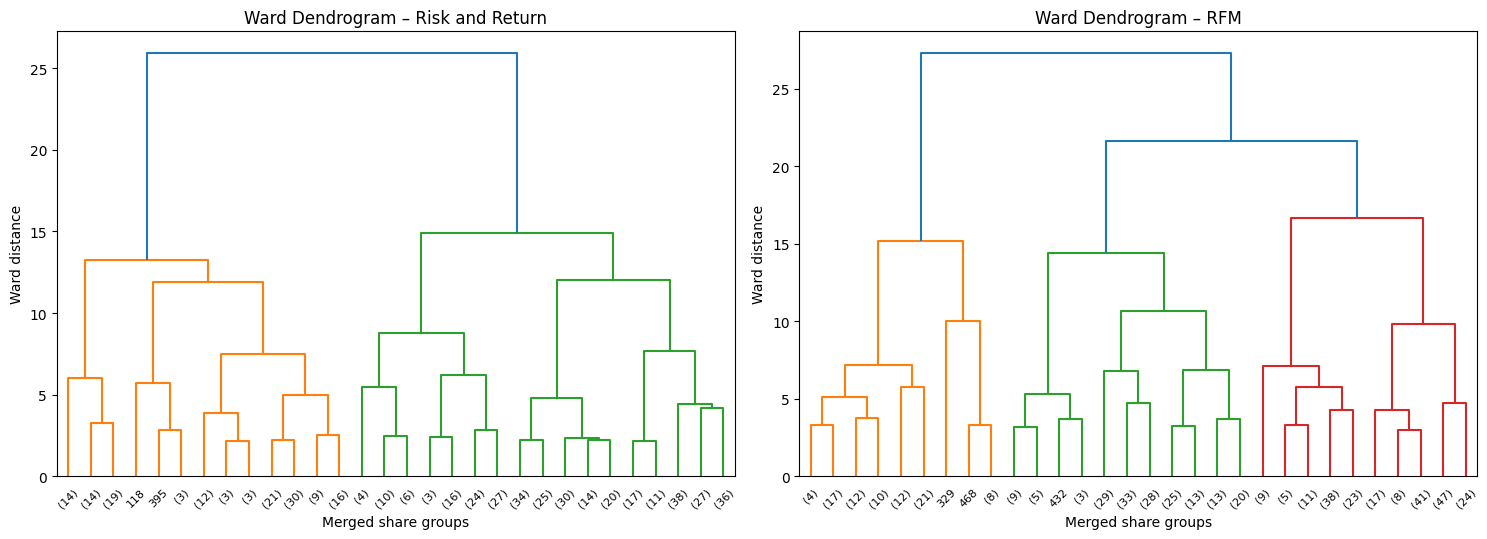

In [66]:
# Create hierarchical linkage matrices using Ward linkage
# and Euclidean distance.

risk_linkage = linkage(
    risk_scaled,
    method='ward',
    metric='euclidean'
)

rfm_linkage = linkage(
    rfm_scaled,
    method='ward',
    metric='euclidean'
)


# Display both Ward dendrograms side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Risk and return dendrogram
plt.sca(axes[0])

dendrogram(
    risk_linkage,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True,
    leaf_font_size=8
)

axes[0].set_title('Ward Dendrogram – Risk and Return')
axes[0].set_xlabel('Merged share groups')
axes[0].set_ylabel('Ward distance')


# RFM dendrogram
plt.sca(axes[1])

dendrogram(
    rfm_linkage,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True,
    leaf_font_size=8
)

axes[1].set_title('Ward Dendrogram – RFM')
axes[1].set_xlabel('Merged share groups')
axes[1].set_ylabel('Ward distance')


# Improve spacing and fit both charts into one figure
plt.tight_layout()
plt.show()

Evaluate Ward clustering for k = 2 to 8

In [67]:
# Evaluate Ward clustering using silhouette scores and cluster sizes.

def evaluate_ward(data, model_name):

    results = []
    cluster_labels = {}

    for k in range(2, 9):

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage='ward',
            metric='euclidean'
        )

        labels = model.fit_predict(data)

        cluster_sizes = pd.Series(labels).value_counts().sort_index()

        silhouette = silhouette_score(data, labels)

        results.append({
            'Model': model_name,
            'k': k,
            'Silhouette': silhouette,
            'Cluster_Sizes': cluster_sizes.to_dict(),
            'Smallest_Cluster': cluster_sizes.min(),
            'Largest_Cluster': cluster_sizes.max()
        })

        cluster_labels[k] = labels

    return pd.DataFrame(results), cluster_labels


# Evaluate both feature matrices
ward_risk_results, ward_risk_labels = evaluate_ward(
    risk_scaled,
    'Ward Risk and Return'
)

ward_rfm_results, ward_rfm_labels = evaluate_ward(
    rfm_scaled,
    'Ward RFM'
)


# Combine the results
ward_evaluation = pd.concat(
    [ward_risk_results, ward_rfm_results],
    ignore_index=True
)

display(ward_evaluation)

,Model,k,Silhouette,Cluster_Sizes,Smallest_Cluster,Largest_Cluster
0,Ward Risk and Return,2,0.376002,"{0: 342, 1: 146}",146,342
1,Ward Risk and Return,3,0.279522,"{0: 146, 1: 252, 2: 90}",90,252
2,Ward Risk and Return,4,0.295954,"{0: 252, 1: 99, 2: 90, 3: 47}",47,252
3,Ward Risk and Return,5,0.267454,"{0: 99, 1: 129, 2: 90, 3: 47, 4: 123}",47,129
4,Ward Risk and Return,6,0.288360,"{0: 90, 1: 129, 2: 94, 3: 47, 4: 123, 5: 5}",5,129
5,Ward Risk and Return,7,0.293636,"{0: 129, 1: 70, 2: 94, 3: 47, 4: 123, 5: 5, 6:...",5,129
6,Ward Risk and Return,8,0.294480,"{0: 94, 1: 70, 2: 5, 3: 47, 4: 123, 5: 101, 6:...",5,123
7,Ward RFM,2,0.369340,"{0: 402, 1: 86}",86,402
8,Ward RFM,3,0.261434,"{0: 223, 1: 86, 2: 179}",86,223
9,Ward RFM,4,0.251355,"{0: 86, 1: 137, 2: 179, 3: 86}",86,179


Identify suggested Ward cluster counts

In [68]:
# Identify the k value with the highest silhouette score.
# These are initial suggestions and must be reviewed
# alongside cluster sizes and the resulting profiles.

ward_risk_k = int(
    ward_risk_results.loc[
        ward_risk_results['Silhouette'].idxmax(), 'k'
    ]
)

ward_rfm_k = int(
    ward_rfm_results.loc[
        ward_rfm_results['Silhouette'].idxmax(), 'k'
    ]
)

print("Suggested Ward risk and return clusters:", ward_risk_k)
print("Suggested Ward RFM clusters:", ward_rfm_k)

Suggested Ward risk and return clusters: 2
Suggested Ward RFM clusters: 2


####**2.3 K-means clustering**
#####Evaluate K-means for k = 2 to 8

In [69]:
# Evaluate K-means using a fixed random seed
# and 50 initialisations for each cluster count.

def evaluate_kmeans(data, model_name):

    results = []
    fitted_models = {}

    for k in range(2, 9):

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=50
        )

        labels = model.fit_predict(data)

        cluster_sizes = pd.Series(labels).value_counts().sort_index()

        silhouette = silhouette_score(data, labels)

        results.append({
            'Model': model_name,
            'k': k,
            'Silhouette': silhouette,
            'Inertia': model.inertia_,
            'Cluster_Sizes': cluster_sizes.to_dict(),
            'Smallest_Cluster': cluster_sizes.min(),
            'Largest_Cluster': cluster_sizes.max()
        })

        fitted_models[k] = model

    return pd.DataFrame(results), fitted_models


# Evaluate both feature matrices
kmeans_risk_results, kmeans_risk_models = evaluate_kmeans(
    risk_scaled,
    'K-means Risk and Return'
)

kmeans_rfm_results, kmeans_rfm_models = evaluate_kmeans(
    rfm_scaled,
    'K-means RFM'
)


# Combine the results
kmeans_evaluation = pd.concat(
    [kmeans_risk_results, kmeans_rfm_results],
    ignore_index=True
)

display(kmeans_evaluation)

,Model,k,Silhouette,Inertia,Cluster_Sizes,Smallest_Cluster,Largest_Cluster
0,K-means Risk and Return,2,0.389176,624.889298,"{0: 347, 1: 141}",141,347
1,K-means Risk and Return,3,0.329303,463.762351,"{0: 119, 1: 165, 2: 204}",119,204
2,K-means Risk and Return,4,0.326067,373.183321,"{0: 39, 1: 116, 2: 162, 3: 171}",39,171
3,K-means Risk and Return,5,0.339689,310.774775,"{0: 173, 1: 50, 2: 129, 3: 30, 4: 106}",30,173
4,K-means Risk and Return,6,0.330720,265.887874,"{0: 90, 1: 54, 2: 136, 3: 120, 4: 23, 5: 65}",23,136
5,K-means Risk and Return,7,0.337339,227.068548,"{0: 48, 1: 87, 2: 63, 3: 67, 4: 5, 5: 144, 6: 74}",5,144
6,K-means Risk and Return,8,0.356757,194.814416,"{0: 74, 1: 139, 2: 4, 3: 78, 4: 41, 5: 43, 6: ...",4,139
7,K-means RFM,2,0.423769,1071.585297,"{0: 420, 1: 68}",68,420
8,K-means RFM,3,0.325091,800.746441,"{0: 151, 1: 274, 2: 63}",63,274
9,K-means RFM,4,0.341383,612.475070,"{0: 214, 1: 122, 2: 61, 3: 91}",61,214


Identify suggested K-means cluster counts

In [70]:
# Identify the k value with the highest silhouette score.
# Review inertia and cluster sizes before finalising the choice.

kmeans_risk_k = int(
    kmeans_risk_results.loc[
        kmeans_risk_results['Silhouette'].idxmax(), 'k'
    ]
)

kmeans_rfm_k = int(
    kmeans_rfm_results.loc[
        kmeans_rfm_results['Silhouette'].idxmax(), 'k'
    ]
)

print("Suggested K-means risk and return clusters:", kmeans_risk_k)
print("Suggested K-means RFM clusters:", kmeans_rfm_k)

Suggested K-means risk and return clusters: 2
Suggested K-means RFM clusters: 2


####**2.4 Cluster profiles and algorithm comparison**
Create the four final cluster assignments

In [71]:
# Use the selected cluster counts to obtain final labels.

ward_risk_final = ward_risk_labels[ward_risk_k]
ward_rfm_final = ward_rfm_labels[ward_rfm_k]

kmeans_risk_final = kmeans_risk_models[
    kmeans_risk_k
].labels_

kmeans_rfm_final = kmeans_rfm_models[
    kmeans_rfm_k
].labels_


# Store all four cluster assignments for the same shares.

cluster_assignments = pd.DataFrame(
    index=clustering_data.index
)

cluster_assignments['Ward_Risk_Return'] = ward_risk_final
cluster_assignments['KMeans_Risk_Return'] = kmeans_risk_final
cluster_assignments['Ward_RFM'] = ward_rfm_final
cluster_assignments['KMeans_RFM'] = kmeans_rfm_final

display(cluster_assignments.head())

,Ward_Risk_Return,KMeans_Risk_Return,Ward_RFM,KMeans_RFM
Share,,,,
A,0,0,0,0
AAPL,1,1,0,0
ABBV,0,0,0,0
ABNB,1,0,0,0
ABT,0,0,0,0


Compare cluster profiles in original units

In [72]:
# Use original, unstandardised values for interpretation.

risk_profile_data = clustering_data[
    ['Mean_Weekly_Return', 'Weekly_Beta']
].copy()

rfm_profile_data = clustering_data[
    ['Recency', 'Frequency', 'Monetary']
].copy()


def show_cluster_profiles(data, labels, model_name):

    profile_data = data.copy()
    profile_data['Cluster'] = labels

    print(model_name, '- mean values')
    display(
        profile_data.groupby('Cluster').mean().round(4)
    )

    print(model_name, '- median values')
    display(
        profile_data.groupby('Cluster').median().round(4)
    )

    print(model_name, '- cluster sizes')
    display(
        profile_data['Cluster']
        .value_counts()
        .sort_index()
        .rename('Share_Count')
        .to_frame()
    )


# Risk and return profiles
show_cluster_profiles(
    risk_profile_data,
    ward_risk_final,
    'Ward Risk and Return'
)

show_cluster_profiles(
    risk_profile_data,
    kmeans_risk_final,
    'K-means Risk and Return'
)


# RFM profiles
show_cluster_profiles(
    rfm_profile_data,
    ward_rfm_final,
    'Ward RFM'
)

show_cluster_profiles(
    rfm_profile_data,
    kmeans_rfm_final,
    'K-means RFM'
)

Ward Risk and Return - mean values


,Mean_Weekly_Return,Weekly_Beta
Cluster,,
0,0.001900,0.808100
1,0.005000,1.370300


Ward Risk and Return - median values


,Mean_Weekly_Return,Weekly_Beta
Cluster,,
0,0.002000,0.823800
1,0.004800,1.329400


Ward Risk and Return - cluster sizes


,Share_Count
Cluster,
0,342
1,146


... (14 outputs left out)

K-means RFM - median values


,Recency,Frequency,Monetary
Cluster,,,
0,11.000000,3.000000,15569619063.227800
1,55.000000,2.000000,22250044924.028801


K-means RFM - cluster sizes


,Share_Count
Cluster,
0,420
1,68


Compare Ward and K-means membership

In [73]:
# Compare cluster membership using Adjusted Rand Index (ARI).
# ARI is unaffected by differences in cluster label numbering.

algorithm_comparison = pd.DataFrame({
    'Feature_Matrix': [
        'Risk and Return',
        'RFM'
    ],

    'Ward_k': [
        ward_risk_k,
        ward_rfm_k
    ],

    'KMeans_k': [
        kmeans_risk_k,
        kmeans_rfm_k
    ],

    'Adjusted_Rand_Index': [
        adjusted_rand_score(
            ward_risk_final,
            kmeans_risk_final
        ),

        adjusted_rand_score(
            ward_rfm_final,
            kmeans_rfm_final
        )
    ]
})

display(algorithm_comparison.round(4))

,Feature_Matrix,Ward_k,KMeans_k,Adjusted_Rand_Index
0,Risk and Return,2,2,0.845700
1,RFM,2,2,0.779600


Produce labelled two-dimensional PCA visualisations

PCA – Ward Risk and Return Clusters - Total variance explained by two components: 100.0 %
PCA – Ward RFM Clusters - Total variance explained by two components: 79.44 %
PCA – K-means Risk and Return Clusters - Total variance explained by two components: 100.0 %
PCA – K-means RFM Clusters - Total variance explained by two components: 79.44 %


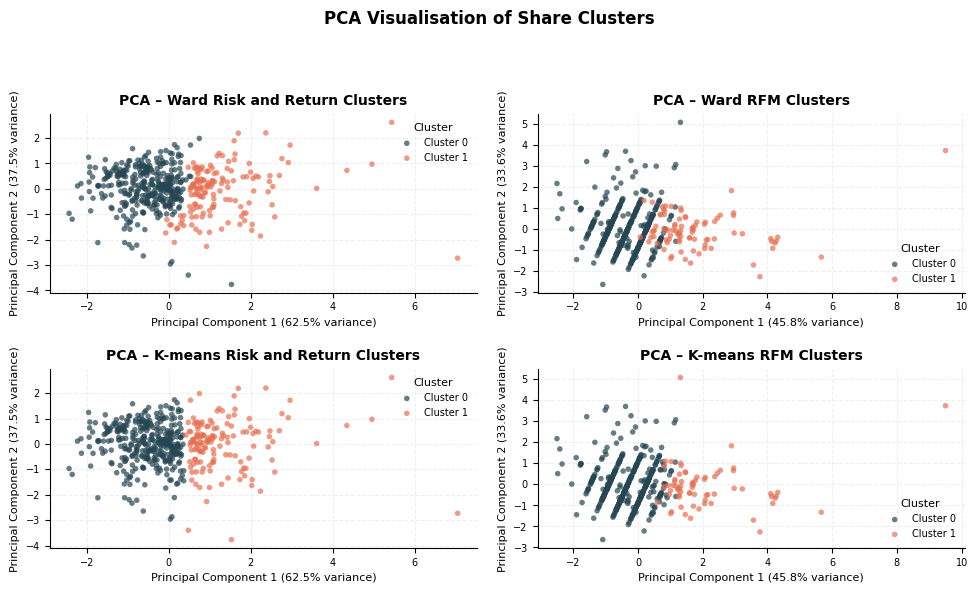

In [74]:
# Use PCA to reduce the standardised features to two dimensions.
# PCA is used only for visualisation; clustering uses the original
# standardised feature matrices.

from matplotlib.patches import Patch

# Define a consistent colour theme for all four visualisations
cluster_colours = ['#264653', '#E76F51', '#2A9D8F', '#E9C46A']


def plot_pca_clusters(data, labels, title, ax):

    pca = PCA(n_components=2)

    coordinates = pca.fit_transform(data)

    unique_labels = np.unique(labels)

    # Plot each cluster separately to ensure the legend colours
    # exactly match the colours used for the data points
    for i, cluster in enumerate(unique_labels):

        cluster_colour = cluster_colours[i % len(cluster_colours)]

        ax.scatter(
            coordinates[labels == cluster, 0],
            coordinates[labels == cluster, 1],
            color=cluster_colour,
            s=16,
            alpha=0.7,
            edgecolors='none',
            label=f'Cluster {cluster}'
        )

    # Format the chart title
    ax.set_title(
        title,
        fontsize=10,
        fontweight='bold',
        pad=7
    )

    # Label the principal components
    ax.set_xlabel(
        'Principal Component 1 '
        f'({pca.explained_variance_ratio_[0]:.1%} variance)',
        fontsize=8
    )

    ax.set_ylabel(
        'Principal Component 2 '
        f'({pca.explained_variance_ratio_[1]:.1%} variance)',
        fontsize=8
    )

    # Display the correct colour indicators
    ax.legend(
        title='Cluster',
        fontsize=7,
        title_fontsize=8,
        frameon=False,
        loc='best'
    )

    # Improve chart appearance
    ax.tick_params(axis='both', labelsize=7)

    ax.grid(
        linestyle='--',
        alpha=0.2
    )

    ax.set_axisbelow(True)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Display the total variance explained
    print(
        title,
        '- Total variance explained by two components:',
        round(pca.explained_variance_ratio_.sum() * 100, 2),
        '%'
    )


# Create one compact 2 × 2 figure
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(10, 6),
    dpi=100
)

axes = axes.flatten()

# Ward risk and return
plot_pca_clusters(
    risk_scaled,
    ward_risk_final,
    'PCA – Ward Risk and Return Clusters',
    axes[0]
)

# Ward RFM
plot_pca_clusters(
    rfm_scaled,
    ward_rfm_final,
    'PCA – Ward RFM Clusters',
    axes[1]
)

# K-means risk and return
plot_pca_clusters(
    risk_scaled,
    kmeans_risk_final,
    'PCA – K-means Risk and Return Clusters',
    axes[2]
)

# K-means RFM
plot_pca_clusters(
    rfm_scaled,
    kmeans_rfm_final,
    'PCA – K-means RFM Clusters',
    axes[3]
)

# Add the overall heading
fig.suptitle(
    'PCA Visualisation of Share Clusters',
    fontsize=12,
    fontweight='bold',
    y=0.99
)

# Adjust spacing to fit the four charts on one screen
plt.tight_layout(
    rect=[0, 0, 1, 0.95],
    pad=1.5
)

plt.show()

Save the cluster assignment table

In [75]:
# Save the four baseline cluster assignments.

cluster_assignments.to_csv(
    'share_cluster_assignments.csv'
)

print("Cluster assignments saved successfully.")

Cluster assignments saved successfully.


####**2.5 RFM sensitivity and correlated inputs**
Calculate correlations between R, F and log1p(M)

Pearson correlation matrix:


,Recency,Frequency,log1p_Monetary
Recency,1.000000,-0.346100,0.152800
Frequency,-0.346100,1.000000,0.012800
log1p_Monetary,0.152800,0.012800,1.000000


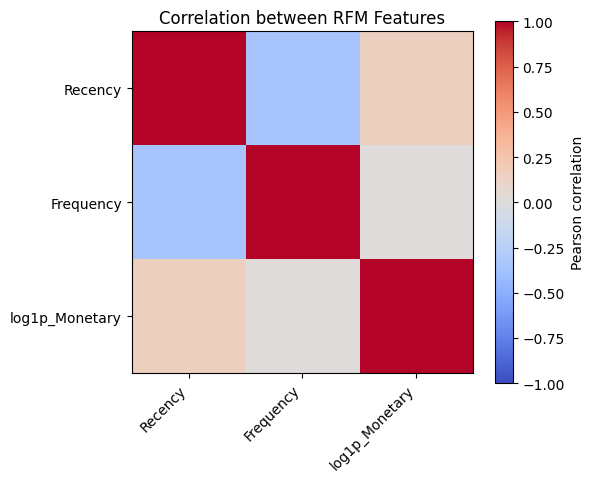

In [76]:
# Calculate Pearson correlations among the three RFM features.

rfm_correlation = rfm_transformed[
    ['Recency', 'Frequency', 'Monetary']
].copy()

rfm_correlation = rfm_correlation.rename(
    columns={'Monetary': 'log1p_Monetary'}
)

correlation_matrix = rfm_correlation.corr(
    method='pearson'
)

print("Pearson correlation matrix:")
display(correlation_matrix.round(4))


# Display the correlations as a heatmap.

plt.figure(figsize=(6, 5))

plt.imshow(
    correlation_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.colorbar(label='Pearson correlation')

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)

plt.title('Correlation between RFM Features')

plt.tight_layout()
plt.show()

Repeat Ward RFM clustering without Monetary

In [77]:
# Remove Monetary and retain Recency and Frequency only.

rf_only = clustering_data[
    ['Recency', 'Frequency']
].copy()


# Fit a new scaler because the feature matrix has changed.

rf_scaler = StandardScaler()

rf_scaled = pd.DataFrame(
    rf_scaler.fit_transform(rf_only),
    index=rf_only.index,
    columns=rf_only.columns
)


# Repeat Ward clustering using the original selected RFM cluster count.
# The same shares and same k are retained for a fair comparison.

ward_rf_model = AgglomerativeClustering(
    n_clusters=ward_rfm_k,
    linkage='ward',
    metric='euclidean'
)

ward_rf_labels = ward_rf_model.fit_predict(rf_scaled)


# Compare the original Ward RFM membership with the reduced R/F membership.

rfm_sensitivity_ari = adjusted_rand_score(
    ward_rfm_final,
    ward_rf_labels
)

print(
    "Adjusted Rand Index after removing Monetary:",
    round(rfm_sensitivity_ari, 4)
)

Adjusted Rand Index after removing Monetary: 0.9225


Compare traded value profiles before and after removing Monetary

In [78]:
# Compare Monetary values under the original RFM clusters
# and the reduced R/F-only clusters.

monetary_comparison = pd.DataFrame({
    'Monetary': clustering_data['Monetary'],
    'Original_Ward_RFM_Cluster': ward_rfm_final,
    'Reduced_Ward_RF_Cluster': ward_rf_labels
})


print("Monetary profile by original Ward RFM clusters")

display(
    monetary_comparison.groupby(
        'Original_Ward_RFM_Cluster'
    )['Monetary'].agg(
        ['count', 'mean', 'median']
    ).round(2)
)

Monetary profile by original Ward RFM clusters


,count,mean,median
Original_Ward_RFM_Cluster,,,
0,402,37389256823.209999,15395754458.170000
1,86,48248051884.199997,21450079938.299999


Display the sensitivity result

In [79]:
# Summarise the effect of removing Monetary.

sensitivity_result = pd.DataFrame({
    'Comparison': [
        'Ward RFM versus Ward R/F only'
    ],

    'Selected_k': [
        ward_rfm_k
    ],

    'Adjusted_Rand_Index': [
        rfm_sensitivity_ari
    ]
})

display(sensitivity_result.round(4))

,Comparison,Selected_k,Adjusted_Rand_Index
0,Ward RFM versus Ward R/F only,2,0.922500


In [80]:
# Export the final Task 2 outputs required for Task 3

# 1. Combine original share features with all four cluster assignments
task2_feature_table_with_clusters = clustering_data.join(
    cluster_assignments
)

task2_feature_table_with_clusters.to_csv(
    'task2_feature_table_with_clusters.csv'
)


# 2. Export Ward clustering evaluation results
ward_evaluation.to_csv(
    'ward_evaluation_table.csv',
    index=False
)


# 3. Export K-means clustering evaluation results
kmeans_evaluation.to_csv(
    'kmeans_evaluation_table.csv',
    index=False
)


# 4. Export the RFM correlation matrix
correlation_matrix.to_csv(
    'rfm_correlation_table.csv'
)


print("Task 2 output files exported successfully.")

print("\nExported files:")
print("1. task2_feature_table_with_clusters.csv")
print("2. ward_evaluation_table.csv")
print("3. kmeans_evaluation_table.csv")
print("4. rfm_correlation_table.csv")

Task 2 output files exported successfully.

Exported files:
1. task2_feature_table_with_clusters.csv
2. ward_evaluation_table.csv
3. kmeans_evaluation_table.csv
4. rfm_correlation_table.csv


##**Task 3**
####**3.2.1 Cluster profiles and sector composition**

In [81]:
# Check that the Task 1 and Task 2 data are available

print("Sector dataset available:", 'sp500_df' in globals())
print("Clustering dataset available:", 'clustering_data' in globals())
print("Cluster assignments available:", 'cluster_assignments' in globals())

# Check the sector columns
display(
    sp500_df[
        ['Symbol', 'Yahoo_Ticker', 'GICS Sector']
    ].head()
)

# Check the cluster assignments
display(cluster_assignments.head())

Sector dataset available: True
Clustering dataset available: True
Cluster assignments available: True


,Symbol,Yahoo_Ticker,GICS Sector
0,MMM,MMM,Industrials
1,AOS,AOS,Industrials
2,ABT,ABT,Health Care
3,ABBV,ABBV,Health Care
4,ACN,ACN,Information Technology


,Ward_Risk_Return,KMeans_Risk_Return,Ward_RFM,KMeans_RFM
Share,,,,
A,0,0,0,0
AAPL,1,1,0,0
ABBV,0,0,0,0
ABNB,1,0,0,0
ABT,0,0,0,0


Match the share tickers to their sectors

In [82]:
# Prepare the sector information for matching

sector_lookup = sp500_df[
    ['Yahoo_Ticker', 'GICS Sector']
].copy()

# Remove duplicate ticker records
sector_lookup = sector_lookup.drop_duplicates(
    subset='Yahoo_Ticker'
)

# Create a ticker-to-sector mapping
sector_map = sector_lookup.set_index(
    'Yahoo_Ticker'
)['GICS Sector']


# Combine the Task 2 share features and cluster assignments
sector_cluster_data = clustering_data.join(
    cluster_assignments
)

# Attach the GICS sector to each share
sector_cluster_data['GICS_Sector'] = (
    sector_cluster_data.index.map(sector_map)
)


# Check the matching results
print("Total shares:", len(sector_cluster_data))

print(
    "Shares successfully matched:",
    sector_cluster_data['GICS_Sector'].notna().sum()
)

print(
    "Shares without sector information:",
    sector_cluster_data['GICS_Sector'].isna().sum()
)

display(sector_cluster_data.head())

Total shares: 488
Shares successfully matched: 488
Shares without sector information: 0


,Mean_Weekly_Return,Weekly_Beta,Aligned_Weekly_Observations,Observation_Date,Latest_High_Volume_Date,Recency,Frequency,Monetary,Ward_Risk_Return,KMeans_Risk_Return,Ward_RFM,KMeans_RFM,GICS_Sector
Share,,,,,,,,,,,,,
A,0.001159,1.076536,206,2024-12-31,2024-12-20,11.000000,2,14001795716.048431,0,0,0,0,Health Care
AAPL,0.004129,1.171262,206,2024-12-31,2024-12-20,11.000000,2,623303377706.584229,1,1,0,0,Information Technology
ABBV,0.003562,0.433191,206,2024-12-31,2024-12-20,11.000000,3,68370537641.661072,0,0,0,0,Health Care
ABNB,0.000851,1.498962,206,2024-12-31,2024-12-20,11.000000,3,36528503216.287994,1,0,0,0,Consumer Discretionary
ABT,0.000970,0.585295,206,2024-12-31,2024-12-20,11.000000,1,35230272606.274414,0,0,0,0,Health Care


Generate the four sector composition tables

In [83]:
# Generate sector composition tables for all four cluster solutions

cluster_columns = [
    'Ward_Risk_Return',
    'KMeans_Risk_Return',
    'Ward_RFM',
    'KMeans_RFM'
]

for cluster_column in cluster_columns:

    print("\nSector composition:", cluster_column)

    sector_table = pd.crosstab(
        sector_cluster_data[cluster_column],
        sector_cluster_data['GICS_Sector'],
        normalize='index'
    ) * 100

    display(sector_table.round(2))


Sector composition: Ward_Risk_Return


GICS_Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_Risk_Return,,,,,,,,,,,
0,4.390000,7.600000,9.060000,3.800000,16.370000,15.500000,14.910000,6.730000,5.560000,7.890000,8.190000
1,3.420000,14.380000,0.680000,4.790000,12.330000,3.420000,19.180000,34.930000,3.420000,2.050000,1.370000



Sector composition: KMeans_Risk_Return


GICS_Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_Risk_Return,,,,,,,,,,,
0,4.320000,7.200000,8.930000,3.460000,16.430000,16.140000,14.410000,7.490000,5.760000,7.780000,8.070000
1,3.550000,15.600000,0.710000,5.670000,12.060000,1.420000,20.570000,34.040000,2.840000,2.130000,1.420000



Sector composition: Ward_RFM


GICS_Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RFM,,,,,,,,,,,
0,4.480000,9.200000,6.470000,4.480000,15.170000,12.690000,17.410000,13.430000,3.980000,7.460000,5.220000
1,2.330000,11.630000,6.980000,2.330000,15.120000,8.140000,10.470000,23.260000,9.300000,0.000000,10.470000



Sector composition: KMeans_RFM


GICS_Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RFM,,,,,,,,,,,
0,4.290000,9.290000,6.430000,4.520000,15.240000,11.900000,17.620000,14.290000,4.290000,7.140000,5.000000
1,2.940000,11.760000,7.350000,1.470000,14.710000,11.760000,7.350000,20.590000,8.820000,0.000000,13.240000


Generate the sector composition charts

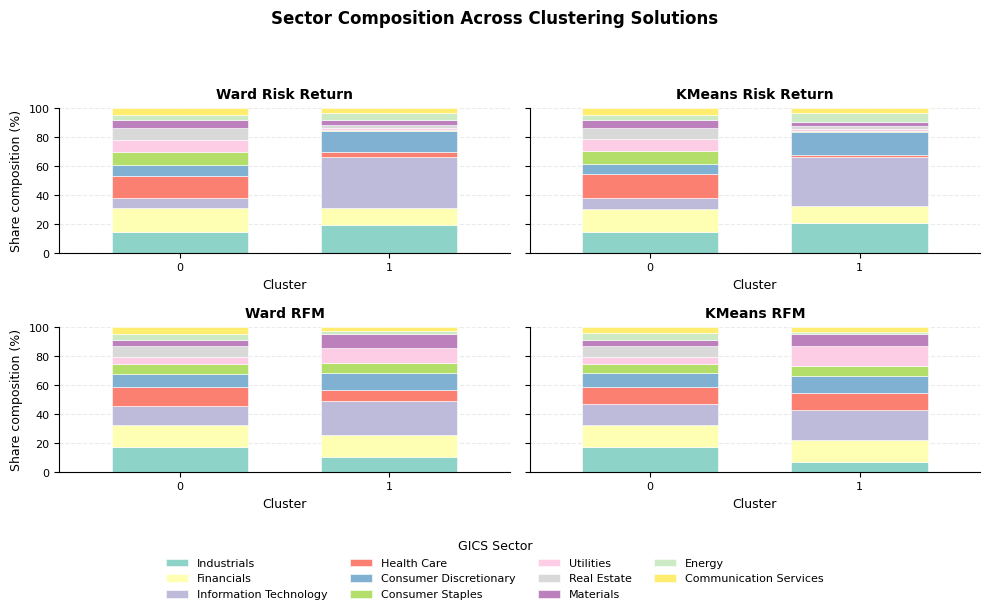

In [84]:
# Visualise sector composition for all four clustering solutions

cluster_columns = [
    'Ward_Risk_Return',
    'KMeans_Risk_Return',
    'Ward_RFM',
    'KMeans_RFM'
]

# Prepare sector data and remove any unmatched sector records
plot_data = sector_cluster_data.dropna(subset=['GICS_Sector']).copy()

# Use the same sector order in all four charts
sector_order = plot_data['GICS_Sector'].value_counts().index.tolist()

# Create one consistent colour for each sector
sector_colours = plt.cm.Set3(
    np.linspace(0, 1, len(sector_order))
)

# Create a compact 2 × 2 figure
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(10, 6),
    sharey=True
)

axes = axes.flatten()

# Create one chart for each clustering solution
for ax, cluster_column in zip(axes, cluster_columns):

    # Calculate sector composition as percentages within each cluster
    sector_table = pd.crosstab(
        plot_data[cluster_column],
        plot_data['GICS_Sector'],
        normalize='index'
    ) * 100

    # Keep sector ordering consistent
    sector_table = sector_table.reindex(
        columns=sector_order,
        fill_value=0
    )

    # Plot a stacked bar chart
    sector_table.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=sector_colours,
        width=0.65,
        edgecolor='white',
        linewidth=0.4,
        legend=False
    )

    # Format each chart
    ax.set_title(
        cluster_column.replace('_', ' '),
        fontsize=10,
        fontweight='bold',
        pad=7
    )

    ax.set_xlabel('Cluster', fontsize=9)
    ax.set_ylabel('Share composition (%)', fontsize=9)
    ax.set_ylim(0, 100)

    ax.tick_params(axis='x', labelsize=8, rotation=0)
    ax.tick_params(axis='y', labelsize=8)

    ax.grid(axis='y', linestyle='--', alpha=0.25)
    ax.set_axisbelow(True)

    # Remove unnecessary chart borders
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Add one shared legend for all four charts
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='GICS Sector',
    loc='lower center',
    bbox_to_anchor=(0.5, -0.01),
    ncol=4,
    fontsize=8,
    title_fontsize=9,
    frameon=False
)

# Add an overall heading and adjust spacing
fig.suptitle(
    'Sector Composition Across Clustering Solutions',
    fontsize=12,
    fontweight='bold',
    y=0.99
)

plt.tight_layout(rect=[0, 0.13, 1, 0.94])
plt.show()

In [85]:
# Save the share-level dataset with sector and cluster information

sector_cluster_data.to_csv(
    'task3_sector_cluster_data.csv'
)


# Save each sector composition table

for cluster_column in cluster_columns:

    sector_table = pd.crosstab(
        sector_cluster_data[cluster_column],
        sector_cluster_data['GICS_Sector'],
        normalize='index'
    ) * 100

    sector_table.to_csv(
        'sector_composition_' + cluster_column + '.csv'
    )

print("Sector composition files saved successfully.")

Sector composition files saved successfully.
